# Fit to TNG S(Z, z)

In [1]:
import sys
import h5py as h5
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u

from scipy import interpolate
from scipy.optimize import minimize

from astropy.cosmology import Planck18  as cosmo # Planck 15 for TNG, Planck 13 for EAGLE, Planck 18 for COLIBRE

############################
# Custom scripts
sys.path.append('../')
import get_ZdepSFRD as Z_SFRD
import paths
from Fit_model_TNG_SFRD import readTNGdata, interpolate_TNGdata, calc_chi_square, test_chi

In [2]:
#Change file names to match TNG version 
tng= 'TNG300-2'
ver = 2
Cosmol_sim_location = paths.data / str("SFRMetallicityFromGasWithMetals%s.hdf5"%(tng))
fit_filename = 'test_best_fit_parameters_%s.txt'%(tng)

if 'TNG50' in tng:
    rbox=35
elif 'TNG100' in tng:
    rbox=75
elif 'TNG300' in tng:
    rbox=205

Zsun = 0.014 #Solar metallicity

# Different intepolation methods 
if tng=='TNG300-1':
    minimize_method = 'nelder-mead' #nelder-mead, BFGS
elif ver>1:
    minimize_method = 'nelder-mead' #nelder-mead, BFGS
else:
    minimize_method = 'nelder-mead'

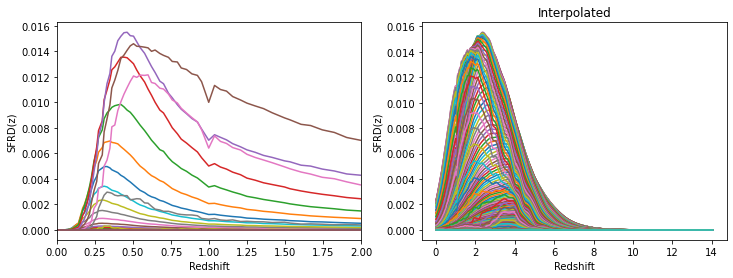

In [3]:
#Read the TNG data and interpolate it
Sim_SFRD, Lookbacktimes, Redshifts, Sim_center_Zbin, step_fit_logZ = readTNGdata(tng, loc = Cosmol_sim_location, rbox=rbox, metals=False)
SFRDnew, redshift_new, Lookbacktimes_new, metals_new, step_fit_logZ_new = interpolate_TNGdata(Redshifts, Lookbacktimes, Sim_SFRD, 
                                                                                                Sim_center_Zbin, saveplot=True, tng=tng, ver=ver, 
                                                                                                redshiftlimandstep=[0, 14.1, 0.05], Nmetals=500)

#SFRDnew, redshift_new, Lookbacktimes_new, metals_new, step_fit_logZ_new = Sim_SFRD.T, Redshifts, Lookbacktimes, Sim_center_Zbin, step_fit_logZ

In [4]:
#Fit the model to the data and save to output file

x0     = np.array([-0.15, 0.026, 1.1, 0.1, -3.3, 0.01, 2.6, 3.2, 6.2]) #best guess
#        # mu_z        # mu_0     # omega_0 #omega_z  #alpha       #sf_a       #sf_b       #sf_c       #sf_d
bounds = ((-1., 0), (0.001, 0.1), (0.01, 5), (0, 1.), (-10, 0), (None,None),(None,None),(None,None),(None,None))

# FIT
if minimize_method=='BFGS':
    res = minimize(test_chi, args=(metals_new, redshift_new, SFRDnew.T), x0= x0, method = 'BFGS',options = {'gtol': 0.05})

else:
    res = minimize(test_chi, args=(metals_new, redshift_new, SFRDnew.T),  x0= x0, method=minimize_method, options = {'maxiter' : 2000})


print(res.success, res.message, 'N iterations: ', res.nit)
muz_best, mu0_best, sigma0_best, sigmaz_best, alpha_best = res.x[0], res.x[1], res.x[2], res.x[3],res.x[4]
sf_a_best, sf_b_best, sf_c_best, sf_d_best               = res.x[5], res.x[6], res.x[7], res.x[8] 

print('\nBEST FITTING PARAMETERS:')
print('mu0 =%s, muz =%s, sigma_0 =%s, sigma_z =%s, alpha=%s'% (mu0_best, muz_best, sigma0_best, sigmaz_best, alpha_best) )
print('sf_a =%s, sf_b =%s, sf_c =%s, sf_d =%s'% (sf_a_best, sf_b_best, sf_c_best, sf_d_best) )

chi_square, data, model = calc_chi_square(metals_new, Redshifts = redshift_new, simulation_SFRD = SFRDnew.T, 
                                muz =muz_best, mu_0 =mu0_best,sigma0 =sigma0_best, sigmaz=sigmaz_best,alpha=alpha_best,
                                sf_a =sf_a_best, sf_b=sf_b_best, sf_c=sf_c_best, sf_d=sf_d_best)
print('chi_square',chi_square, 'max_res_squared', np.amax( (data-model)**2) )

if res.success:
    np.savetxt(paths.data / fit_filename,
            np.c_[mu0_best, muz_best, sigma0_best, sigmaz_best, alpha_best,sf_a_best, sf_b_best, sf_c_best, sf_d_best],
            header = "mu0, muz, omega0, omegaz, alpha0,sf_a, sf_b, sf_c, sf_d", delimiter=',', fmt="%s")

/Users/sashalvna/Research/Fit_SFRD_TNG/get_ZdepSFRD.py:31: RuntimeWarning: divide by zero encountered in divide
  dm_dtdMpc = a * (1 + z)**b/( 1 + ( (1+z)/c )**d ) *u.Msun *u.yr**-1 *u.Mpc**-3
/Users/sashalvna/Research/Fit_SFRD_TNG/get_ZdepSFRD.py:88: RuntimeWarning: divide by zero encountered in log
  xi_metallicities = np.log(mean_metallicities/(2 * PHI)) - (omega**2)/2.   # Now we re-write the expected value to retrieve xi
/Users/sashalvna/Research/Fit_SFRD_TNG/get_ZdepSFRD.py:99: RuntimeWarning: invalid value encountered in log
  log_metallicities = np.log(metallicities)
/Users/sashalvna/Research/Fit_SFRD_TNG/get_ZdepSFRD.py:106: RuntimeWarning: divide by zero encountered in divide
  dPdlogZ = 2./(omega[:,np.newaxis]) \
/Users/sashalvna/Research/Fit_SFRD_TNG/get_ZdepSFRD.py:107: RuntimeWarning: divide by zero encountered in divide
  * NormDist.pdf((log_metallicities -  xi_metallicities[:,np.newaxis])/omega[:,np.newaxis]) \
/Users/sashalvna/Research/Fit_SFRD_TNG/get_ZdepSFRD.py:106:

ValueError: operands could not be broadcast together with shapes (500,) (500,9) 